In [24]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [25]:
# 1. 定义状态
class CalculatorState(TypedDict):
    num1: float  # 第一个数字
    num2: float  # 第二个数字
    operator: str  # 操作符（+、-、*、/）
    result: float  # 计算结果

In [26]:
# 2. 定义节点
def printer(state: CalculatorState) -> CalculatorState:
    """根据操作符执行计算"""
    num1 = state["num1"]
    num2 = state["num2"]
    operator = state["operator"]
    print(f"准备计算 {num1} {operator} {num2}")
    return state

def add(state: CalculatorState) -> CalculatorState:
    """加法操作"""
    print("执行加法操作")
    state['result'] = state['num1'] + state['num2']
    return state

def subtract(state: CalculatorState) -> CalculatorState:
    """加法操作"""
    print("执行减法操作")
    state['result'] = state['num1'] - state['num2']
    return state

In [27]:
# 定义 printer 节点的条件边
def router(state: CalculatorState) -> str:
    return "add_operation" if state['operator'] == "+" else "sub_operation"

In [28]:
builder = StateGraph(CalculatorState)
builder.add_node("printer", printer)
builder.add_node("add", add)
builder.add_node("subtract", subtract)

builder.add_edge(START, "printer")
builder.add_edge("add", END)
builder.add_edge("subtract", END)
builder.add_conditional_edges(
    "printer",
    router,
    {
        "add_operation": "add",
        "sub_operation": "subtract"
    }
)

graph = builder.compile()

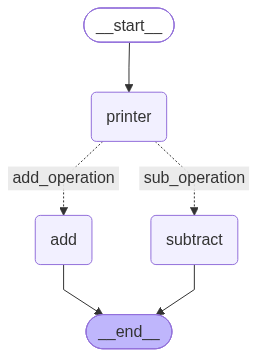

In [29]:
from IPython.display import Image, display
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

In [30]:
result = graph.invoke({
    "num1": 10,
    "num2": 5,
    "operator": "-"
})
print(f"结果：{result['result']}")

准备计算 10 - 5
执行减法操作
结果：5
